# ConvNeXt with a residual spatial block

This run tests one architectural hypothesis: can a small trainable spatial block after ConvNeXt's final feature map help distinguish the three named pets? We start from the same pretrained ConvNeXt and saved fold-0 linear classifier as the unchanged control. The only planned architecture difference is the new residual block before the existing pooling and head.

Match the unchanged control's fold, seed, transforms, optimizer, schedule, effective batch, eight-epoch cap, checkpoint rule and threshold. The new block uses the backbone learning rate, so this is a strict matched recipe; a later higher block learning rate would need its own run ID. The first complete epoch measures checkpoint and optional Drive-backup time and stops the run if its projected total exceeds five hours. Early stopping may finish sooner.

Run the cells from top to bottom. By default they inspect the data but do not download weights, train, write results, or build a submission. A fold-0 score is screening evidence, not five-fold cross-validation or a public leaderboard score. There is no Kaggle upload step.


In [1]:
from __future__ import annotations

import hashlib
import importlib
import os
import platform
import random
import re
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import torch

LOCAL_SMOKE_TEST = os.environ.get('STAGE2_LOCAL_SMOKE_TEST', '0') == '1'
RUN_TRAINING = LOCAL_SMOKE_TEST or os.environ.get('STAGE2_RUN_TRAINING', '0') == '1'
EVAL_CHECKPOINT = os.environ.get('STAGE2_EVAL_CHECKPOINT')
EVAL_RUN_RECORD = os.environ.get('STAGE2_EVAL_RUN_RECORD')
SMOKE_TEST = LOCAL_SMOKE_TEST or os.environ.get('STAGE2_SMOKE_TEST', '1') == '1'
PROFILE_RUNTIME = LOCAL_SMOKE_TEST or os.environ.get('STAGE2_PROFILE_RUNTIME', '0') == '1'
PROFILE_ONLY = os.environ.get('STAGE2_PROFILE_ONLY', '0') == '1'
BACKUP_TO_DRIVE = not LOCAL_SMOKE_TEST and os.environ.get('STAGE2_BACKUP_TO_DRIVE', '0') == '1'
DRIVE_FOLDER_NAME = os.environ.get('STAGE2_DRIVE_FOLDER_NAME', 'AI301-stage2')
DRIVE_ROOT = (Path('/content/drive/MyDrive') / DRIVE_FOLDER_NAME).resolve()
ALLOW_WEIGHT_DOWNLOAD = not LOCAL_SMOKE_TEST and os.environ.get('STAGE2_ALLOW_WEIGHT_DOWNLOAD', '0') == '1'
USE_WANDB = not LOCAL_SMOKE_TEST and os.environ.get('STAGE2_USE_WANDB', '1') == '1'
REMOVE_RUNTIME_ENV_AFTER_LOAD = os.environ.get('STAGE2_REMOVE_RUNTIME_ENV_AFTER_LOAD', '0') == '1'
WANDB_MODE = 'online'
WANDB_PROJECT = 'ai301-stage2'
BUILD_SUBMISSION = False
BUILD_GRADCAM = False
SUBMIT_TO_KAGGLE = False  # No submission API call exists in this notebook.

MODEL_NAME = 'hf-hub:timm/convnext_base.fb_in22k_ft_in1k_384@2b2698d86523262ca8065d0957c7f80d963bb43f'
HEAD_RUN_ID = 'convnext_head_fold0_seed42_colab'
RUN_ID = os.environ.get('STAGE2_RUN_ID', 'convnext_custom_fold0_seed42')
CONTROL_RUN_ID = os.environ.get('STAGE2_CONTROL_RUN_ID')
BLOCK_REDUCTION = 4
SEED = 42
VALIDATION_FOLD = 0
THRESHOLD = 0.25
IMAGE_SIZE = 384
BATCH_SIZE = 2
EFFECTIVE_BATCH_SIZE = 16
MAX_EPOCHS = 8
PATIENCE = 3
MAX_RUN_HOURS = 5.0
BACKBONE_LR = 1e-5
HEAD_LR = 1e-4
WEIGHT_DECAY = 1e-2
NUM_WORKERS = 0
PRECISION = '32-true'
PROFILE_TIMED_UPDATES = 3
PROFILE_VALIDATION_BATCHES = 8

if min(BATCH_SIZE, EFFECTIVE_BATCH_SIZE) < 1 or EFFECTIVE_BATCH_SIZE % BATCH_SIZE:
    raise ValueError('Effective batch size must be divisible by physical batch size.')
if RUN_TRAINING and EVAL_CHECKPOINT:
    raise ValueError('Choose training or an existing checkpoint, not both.')
if bool(EVAL_CHECKPOINT) != bool(EVAL_RUN_RECORD):
    raise ValueError('Saved evaluation requires both STAGE2_EVAL_CHECKPOINT and STAGE2_EVAL_RUN_RECORD.')
if VALIDATION_FOLD != 0:
    raise ValueError('The shared head was trained on folds 1-4; use it only for fold-0 screening.')
if PROFILE_ONLY and (not RUN_TRAINING or SMOKE_TEST):
    raise ValueError('Profile-only mode requires training enabled and smoke mode disabled.')
if PROFILE_RUNTIME and (not RUN_TRAINING or not SMOKE_TEST):
    raise ValueError('Short runtime profiling requires training enabled and smoke mode enabled.')
if PROFILE_TIMED_UPDATES < 2 or PROFILE_VALIDATION_BATCHES < 2:
    raise ValueError('Profile at least two updates after warm-up and two validation batches.')
SMOKE_TRAIN_BATCHES = (1 + PROFILE_TIMED_UPDATES if PROFILE_RUNTIME else 1) * (EFFECTIVE_BATCH_SIZE // BATCH_SIZE)
SMOKE_VALIDATION_BATCHES = PROFILE_VALIDATION_BATCHES if PROFILE_RUNTIME else 4
if BACKUP_TO_DRIVE and not RUN_TRAINING:
    raise ValueError('Drive backup is for a training run.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._-]{0,79}', RUN_ID):
    raise ValueError('STAGE2_RUN_ID must be a single, safe run name.')
if CONTROL_RUN_ID and not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._-]{0,79}', CONTROL_RUN_ID):
    raise ValueError('STAGE2_CONTROL_RUN_ID must be a single, safe run name.')
if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9._ -]{0,79}', DRIVE_FOLDER_NAME):
    raise ValueError('STAGE2_DRIVE_FOLDER_NAME must be one folder name (letters, numbers, spaces, dots, underscores or hyphens).')
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f'Device: {DEVICE}; training: {RUN_TRAINING}; saved checkpoint: {bool(EVAL_CHECKPOINT)}; smoke test: {SMOKE_TEST}; short profile: {PROFILE_RUNTIME}; profile only: {PROFILE_ONLY}; Drive backup: {BACKUP_TO_DRIVE}')


Device: mps; training: True; saved checkpoint: False; smoke test: False; short profile: False; profile only: False; Drive backup: False


## Use the same split as before

The validation notebook already assigned every image to one of five folds. We check that `folds.csv` still matches the seed-42 stratified split, then join it to the labels by image ID. This keeps our model comparisons on the same held-out images. Stratification uses the five-label combinations; one combination has only four images, so it cannot appear in every fold.

For the CNN, we keep the whole photo, resize it to fit inside a 384-pixel square, and pad the rest with the checkpoint's mean colour. Training images may be flipped horizontally; validation and test images are left alone. We use the pretrained checkpoint's RGB mean and standard deviation, not newly calculated dataset statistics. ConvNeXt's own LayerNorm stays in place; no BatchNorm or other new normalization layer is added. The old embedding baseline used different preprocessing, which matters when we compare scores.

In [2]:
start = Path(os.environ.get('STAGE2_ROOT', Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents) if (path / 'folds.csv').is_file() and (path / 'stage2' / 'experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from this repository or a subdirectory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from stage2.experiment import LABEL_COLUMNS, ImageDataset, form_submission, read_csv, score_probabilities, split_rows, verify_saved_stratification, write_probabilities, write_run_record, write_submission
from stage2.train import predict_probabilities
from stage2 import finetune
importlib.reload(finetune)  # Colab CLI may reuse a kernel from an earlier run.
from stage2.finetune import DriveRunBackup, FineTuneClassifier, SmokeRuntimeProfile, TimedBudgetCheckpoint, copy_verified, load_trained_head
from stage2 import custom_convnext
importlib.reload(custom_convnext)  # Colab CLI may reuse a kernel after a helper upload.
from stage2.custom_convnext import CustomConvNeXt

from stage2 import run_records, diagnostics as training_diagnostics
importlib.reload(run_records)
importlib.reload(training_diagnostics)
from stage2.run_records import file_sha256, record_failures, validate_evaluation_record, validate_matched_control
from stage2.diagnostics import TrainingDiagnostics

failure_configuration = {
    'run_id': RUN_ID, 'experiment': '02_convnext_custom', 'fold': VALIDATION_FOLD,
    'seed': SEED, 'model_name': MODEL_NAME, 'smoke_test': SMOKE_TEST,
    'profile_only': PROFILE_ONLY, 'device': str(DEVICE),
    'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY,
    'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'precision': PRECISION,
    'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
    'threshold': THRESHOLD, 'image_size': IMAGE_SIZE, 'block_reduction': BLOCK_REDUCTION,
    'source_sha256': {name: file_sha256(ROOT / name) for name in (
        'notebooks/07_convnext_custom.ipynb', 'stage2/run_records.py', 'stage2/diagnostics.py',
        'stage2/experiment.py', 'stage2/train.py', 'stage2/finetune.py', 'stage2/custom_convnext.py')},
}
run_dir = None
if RUN_TRAINING or EVAL_CHECKPOINT:
    run_name = RUN_ID + ('_evaluation' if EVAL_CHECKPOINT else '_smoke' if SMOKE_TEST else '')
    run_dir = ROOT / 'artifacts' / run_name
    run_dir.mkdir(parents=True, exist_ok=False)

with record_failures(run_dir, failure_configuration, 'data'):
    DATA_DIR = ROOT / 'data'
    combination_counts = verify_saved_stratification(DATA_DIR, ROOT / 'folds.csv', SEED)
    train_rows, validation_rows = split_rows(DATA_DIR, ROOT / 'folds.csv', VALIDATION_FOLD)
    test_rows = read_csv(DATA_DIR / 'test.csv', ('image_id',))
    sample_rows = read_csv(DATA_DIR / 'sample_submission.csv', ('image_id', *LABEL_COLUMNS))
    if {row['image_id'] for row in test_rows} != {row['image_id'] for row in sample_rows}:
        raise ValueError('test.csv and sample_submission.csv have different image IDs.')
    required_images = ((train_rows[0], DATA_DIR / 'train'), (validation_rows[0], DATA_DIR / 'train'))
    if BUILD_SUBMISSION:
        required_images += ((test_rows[0], DATA_DIR / 'test'),)
    for row, directory in required_images:
        if not (directory / f"{row['image_id']}.jpg").is_file():
            raise FileNotFoundError(f'Missing image in {directory}.')
    print(f'{len(train_rows):,} train, {len(validation_rows):,} validation, {len(test_rows):,} test images')
    print('Saved combination-stratified folds verified:', combination_counts)
    print('Positive validation labels:', {label: sum(int(row[label]) for row in validation_rows) for label in LABEL_COLUMNS})

9,808 train, 2,452 validation, 18,673 test images
Saved combination-stratified folds verified: {'00000': 2162, '01000': 4984, '01001': 37, '10000': 4989, '10010': 32, '10100': 42, '10110': 10, '11101': 4}
Positive validation labels: {'Cat': 1015, 'Dog': 1004, 'Moris': 10, 'Motya': 9, 'Biatrix': 8}


## Connect W&B when training starts

For a local run, put `WANDB_API_KEY` in the repo's ignored `.env` file or export it before launching Jupyter. The existing `WB_API_KEY` name also works. In Colab, add a `WANDB_API_KEY` secret and grant the notebook access. The key is read only when online training is enabled; it is never printed or saved in the notebook.

In [3]:
with record_failures(run_dir, failure_configuration, 'credentials'):
    def ensure_wandb_key() -> None:
        key = os.environ.get('WANDB_API_KEY') or os.environ.get('WB_API_KEY')
        env_file = ROOT / '.env'
        if not key and env_file.is_file():
            for line in env_file.read_text().splitlines():
                name, separator, value = line.partition('=')
                if separator and name.strip() in {'WANDB_API_KEY', 'WB_API_KEY'}:
                    key = value.strip().strip("\"'")
                    if key:
                        break
        if key:
            os.environ['WANDB_API_KEY'] = key
            if REMOVE_RUNTIME_ENV_AFTER_LOAD and env_file.is_file() and ROOT.is_relative_to('/content'):
                env_file.unlink()
                print('Removed the temporary Colab credential file.')
            return
        try:
            from google.colab import userdata
        except ImportError:
            raise RuntimeError('Set WANDB_API_KEY in the repo .env file or environment.') from None
        try:
            secret = userdata.get('WANDB_API_KEY')
        except Exception as error:
            raise RuntimeError('Add WANDB_API_KEY to Colab Secrets and grant this notebook access.') from error
        if not secret:
            raise RuntimeError('The WANDB_API_KEY Colab Secret is empty.')
        os.environ['WANDB_API_KEY'] = secret

    if RUN_TRAINING and USE_WANDB and WANDB_MODE == 'online':
        ensure_wandb_key()
        print('W&B online credential is available (value hidden).')
    else:
        print('W&B credential check skipped until online training is enabled.')

W&B online credential is available (value hidden).


## Load the shared start, then add one block

The saved file contains the final linear classifier's weights and bias. We recreate the same pretrained ConvNeXt, install that classifier with a strict check, and only then wrap it with our block. The block narrows channels with a 1×1 convolution, mixes spatial information with a 3×3 depthwise convolution, restores channels with another 1×1 convolution, and adds the original feature map. The final projection starts at zero, so the initial custom model must give exactly the same logits as the unchanged model. No BatchNorm or other new normalization is inserted.

All pretrained and new parameters are trainable. The saved head was trained on folds 1–4 and selected on fold 0; it cannot be reused for another held-out fold. The model produces five logits in the fixed label order. BCEWithLogitsLoss handles each label independently; sigmoid turns logits into probabilities only for evaluation and submission formation.


In [4]:
with record_failures(run_dir, failure_configuration, 'model'):
    if RUN_TRAINING or EVAL_CHECKPOINT:
        if not ALLOW_WEIGHT_DOWNLOAD:
            os.environ['HF_HUB_OFFLINE'] = '1'
        import timm
        import lightning as L
        from lightning.pytorch.callbacks import EarlyStopping, LearningRateMonitor, ModelCheckpoint
        from lightning.pytorch.loggers import CSVLogger
        from torch.utils.data import DataLoader

        L.seed_everything(SEED, workers=True)
        backbone = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABEL_COLUMNS))
        preprocessing = timm.data.resolve_model_data_config(backbone)
        if preprocessing['input_size'][-1] != IMAGE_SIZE:
            raise ValueError(f"Checkpoint expects {preprocessing['input_size']}, not {IMAGE_SIZE}px.")
        head_path = ROOT / 'experiments' / '00_shared_head' / 'checkpoints' / f'{HEAD_RUN_ID}_head.pt'
        load_trained_head(backbone, head_path)
        network = CustomConvNeXt(backbone, reduction=BLOCK_REDUCTION)
        for parameter in network.parameters():
            parameter.requires_grad_(True)
        train_data = ImageDataset(train_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'], horizontal_flip=True)
        validation_data = ImageDataset(validation_rows, DATA_DIR / 'train', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
        loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == 'cuda')
        train_generator = torch.Generator().manual_seed(SEED)
        train_loader = DataLoader(train_data, shuffle=True, generator=train_generator, **loader_options)
        validation_loader = DataLoader(validation_data, shuffle=False, **loader_options)
        _, image, targets = train_data[0]
        assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE) and targets.shape == (5,)
        backbone.eval()
        network.eval()
        with torch.inference_mode():
            reference_logits = backbone(image.unsqueeze(0))
            initial_logits = network(image.unsqueeze(0))
        if initial_logits.shape != (1, len(LABEL_COLUMNS)) or not torch.isfinite(initial_logits).all():
            raise ValueError('The custom model did not return five finite logits.')
        torch.testing.assert_close(initial_logits, reference_logits, rtol=0, atol=0)
        standard_parameters = sum(p.numel() for p in backbone.parameters())
        extra_parameters = sum(p.numel() for p in network.block.parameters())
        print('Initial logits exactly match the unchanged model.')
        print('Normalization:', preprocessing['mean'], preprocessing['std'])
        print(f'Parameters: {standard_parameters:,} pretrained/head + {extra_parameters:,} new = {standard_parameters + extra_parameters:,}')

        run_configuration = {
            'fold': VALIDATION_FOLD, 'seed': SEED,
            'model': {'name': MODEL_NAME, 'variant': 'residual_spatial_block', 'block_reduction': BLOCK_REDUCTION,
                      'extra_parameters': extra_parameters, 'pretrained_checkpoint': MODEL_NAME,
                      'initial_head_checkpoint': str(head_path.relative_to(ROOT)),
                      'initial_head_sha256': file_sha256(head_path), 'control_run_id': CONTROL_RUN_ID},
            'data': {'image_size': IMAGE_SIZE,
                     'transform': 'mean-colour letterbox, bicubic, checkpoint normalization; train horizontal flip p=0.5',
                     'fold_file': 'folds.csv', 'fold_sha256': file_sha256(ROOT / 'folds.csv'),
                     'label_columns': list(LABEL_COLUMNS), 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std'])},
            'training': {'optimizer': f'AdamW(backbone_and_block_lr={BACKBONE_LR}, head_lr={HEAD_LR}, weight_decay={WEIGHT_DECAY} except bias/norm, betas=(0.9, 0.999))',
                         'scheduler': 'one epoch step warmup then cosine to 0.1 peak', 'loss': 'BCEWithLogitsLoss',
                         'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'physical_batch_size': BATCH_SIZE,
                         'effective_batch_size': EFFECTIVE_BATCH_SIZE, 'precision': PRECISION,
                         'stage_policy': 'full backbone, residual block and classifier trainable',
                         'checkpoint_selection': 'best validation macro F1 at 0.25', 'gradient_clip_norm': 1.0},
            'metrics': {'threshold': THRESHOLD},
        }
        failure_configuration.update(run_configuration)
        source_run_record = validate_evaluation_record(
            Path(EVAL_RUN_RECORD).resolve(), Path(EVAL_CHECKPOINT).resolve(), run_configuration,
        ) if EVAL_CHECKPOINT else None
    else:
        print('Model loading skipped.')


/Users/hermanhavva/Documents/Kse/deep_learning/deep-learning-assignment2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Seed set to 42


Initial logits exactly match the unchanged model.
Normalization: [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]
Parameters: 87,571,589 pretrained/head + 528,128 new = 88,099,717


## Check the training path, then time the custom model

For a bounded local check, set the configuration boolean `LOCAL_SMOKE_TEST=True` (or `STAGE2_LOCAL_SMOKE_TEST=1`). This enables training, smoke mode and short profiling, while disabling weight downloads, W&B and Drive. Cached pretrained weights and the saved head must already exist. Use a fresh `STAGE2_RUN_ID`; existing artifacts are never overwritten.

Short profiling runs one warm-up optimizer update, then three timed updates (32 physical batches at the default accumulation), and eight validation batches, excluding the first validation batch from throughput. Device synchronization includes actual forward/backward, clipping, AdamW and image loading. Validation metrics and local checkpoint writing are timed separately. `smoke_profile.json` projects a full fold, eight epochs and final validation with a 10% margin. It is a short-sample estimate, not a full-epoch timing gate or a model-quality result; setup, Drive copies, test inference and thermal drift are excluded. Smoke uses a shortened learning-rate schedule.

For Colab or a separately configured smoke run, use `RUN_TRAINING=True`, `SMOKE_TEST=True`, and optionally `PROFILE_RUNTIME=True`. Without short profiling, smoke uses one accumulated update and four validation batches. Set `SMOKE_TEST=False` and `PROFILE_ONLY=True` for one complete timing epoch using the eight-epoch schedule. Set both to `False` for full training; it still stops after epoch one if its protected projection exceeds five hours. Keep `LOCAL_SMOKE_TEST=False` for either full-fold mode.

As in the control, AdamW uses LR `1e-5` for pretrained layers **and the new block**, and `1e-4` for the final classifier. Weight decay `0.01` applies to eligible weights, not biases or normalization parameters. A step-based scheduler warms the rates during epoch one and cosine-decays them to 10% of their peaks by epoch eight. Physical batch two accumulates to effective batch 16. Per-layer mean/max gradient L2 norms (after unscaling, before clipping) are saved each epoch to `diagnostics/layer_gradients.csv`; the block also has its own gradient curve. `diagnostics/memory.json` records CUDA allocator peaks, sampled MPS allocation/driver high-water marks, or process-lifetime peak RSS on CPU. MPS samples are not true peaks; RSS is not isolated to the run. Failures after run-directory creation save a safe `failure.json` with phase, configuration and exception type/location, then re-raise; exception messages and source lines are omitted to avoid leaking credentials. This also covers interruption, evaluation and artifact-writing failures. Gradient norm is clipped at 1.0. Lightning records losses, fixed-threshold F1, AP, and gradient norms in CSV and W&B; model weights and photos are not sent to W&B.

Drive backup is optional and off by default. For Colab, mount Drive first, set `STAGE2_BACKUP_TO_DRIVE=1`, and choose `STAGE2_DRIVE_FOLDER_NAME` (default `AI301-stage2`). For example, `STAGE2_DRIVE_FOLDER_NAME=AI301-convnext-custom` writes under `/content/drive/MyDrive/AI301-convnext-custom/02_convnext_custom/<run-id>/`. Give each run a unique ID: existing Drive files are never overwritten. The notebook checks the mount with a small write before training.

After each complete epoch, it copies a full resume checkpoint (model, optimizer and scheduler), the best evaluation checkpoint when it changes, and a manifest. It verifies each copy before exposing its final filename. Curves, the timing record, and completed-run results are copied when available. Leave Drive space for multiple large checkpoints; a failed copy stops the run. Fresh-VM resume is not yet automated, and the CLI output-bearing notebook must still be saved separately.


In [5]:
with record_failures(run_dir, failure_configuration, 'training'):
    if RUN_TRAINING:
        drive_backup = None
        if BACKUP_TO_DRIVE:
            if not ROOT.is_relative_to('/content') or not Path('/content/drive/MyDrive').is_dir():
                raise RuntimeError('Mount Google Drive on this Colab runtime before training.')
            if not DRIVE_ROOT.is_relative_to('/content/drive/MyDrive'):
                raise ValueError('The Drive folder must remain under /content/drive/MyDrive.')
            drive_backup = DriveRunBackup(run_dir, DRIVE_ROOT / '02_convnext_custom' / run_name)
        if drive_backup is not None:
            probe = run_dir / 'drive_probe.txt'
            probe.write_text(f'{run_name} Drive write check\n')
            copy_verified(probe, drive_backup.drive_dir / probe.name)
            print('Drive backup available:', drive_backup.drive_dir)
        module = FineTuneClassifier(network, BACKBONE_LR, HEAD_LR, WEIGHT_DECAY, THRESHOLD)
        checkpoint_options = dict(dirpath=run_dir / 'checkpoints', filename='best', monitor='val_macro_f1', mode='max', save_top_k=1, save_weights_only=True, save_on_train_epoch_end=False)
        checkpoint = ModelCheckpoint(**checkpoint_options) if SMOKE_TEST else TimedBudgetCheckpoint(**checkpoint_options, maximum_hours=MAX_RUN_HOURS, profile_only=PROFILE_ONLY, epoch_backup=drive_backup.save_epoch if drive_backup else None)
        diagnostics = TrainingDiagnostics(run_dir / 'diagnostics', {'block': network.block})
        callbacks = [checkpoint, LearningRateMonitor(logging_interval='epoch'), diagnostics]
        runtime_profile = SmokeRuntimeProfile() if PROFILE_RUNTIME else None
        if runtime_profile is not None:
            callbacks.append(runtime_profile)
        if not SMOKE_TEST:
            callbacks.append(EarlyStopping(monitor='val_macro_f1', mode='max', patience=PATIENCE))
        logger = CSVLogger(save_dir=run_dir, name='curves')
        loggers = [logger]
        wandb_logger = None
        if USE_WANDB:
            from lightning.pytorch.loggers import WandbLogger
            wandb_logger = WandbLogger(project=WANDB_PROJECT, name=run_name, save_dir=str(run_dir), offline=False, log_model=False)
            wandb_logger.log_hyperparams({
                'model': MODEL_NAME, 'variant': 'residual_spatial_block', 'block_reduction': BLOCK_REDUCTION, 'control_run_id': CONTROL_RUN_ID,
                'head_run': HEAD_RUN_ID, 'fold': VALIDATION_FOLD, 'seed': SEED,
                'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
                'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY,
                'scheduler': 'one-epoch warmup then cosine to 0.1 peak', 'threshold': THRESHOLD,
                'smoke_test': SMOKE_TEST, 'profile_only': PROFILE_ONLY, 'precision': PRECISION, 'runtime_gate_hours': MAX_RUN_HOURS,
                'max_epochs': MAX_EPOCHS, 'drive_backup': BACKUP_TO_DRIVE, 'drive_folder_name': DRIVE_FOLDER_NAME if BACKUP_TO_DRIVE else None,
            })
            wandb_logger.watch(module.network.get_classifier(), log='gradients', log_freq=50, log_graph=False)
            print('W&B run:', wandb_logger.experiment.url)
            loggers.append(wandb_logger)
        trainer = L.Trainer(
            accelerator=DEVICE.type, devices=1, precision=PRECISION, max_epochs=1 if SMOKE_TEST else MAX_EPOCHS,
            accumulate_grad_batches=EFFECTIVE_BATCH_SIZE // BATCH_SIZE, callbacks=callbacks, logger=loggers,
            limit_train_batches=SMOKE_TRAIN_BATCHES if SMOKE_TEST else 1.0, limit_val_batches=SMOKE_VALIDATION_BATCHES if SMOKE_TEST else 1.0,
            num_sanity_val_steps=0, gradient_clip_val=1.0, log_every_n_steps=1 if SMOKE_TEST else 10,
            enable_progress_bar=False,
            enable_model_summary=False,
        )
        if SMOKE_TEST:
            smoke_parameters = {'backbone': next(backbone.parameters()), 'head': network.get_classifier().weight, 'block': network.block.restore.weight}
            smoke_initial_weights = {name: parameter.detach().cpu().clone() for name, parameter in smoke_parameters.items()}
        if DEVICE.type == 'cuda':
            torch.cuda.reset_peak_memory_stats()
        L.seed_everything(SEED, workers=True)  # Match augmentation draws across architecture variants.
        started = time.perf_counter()
        try:
            trainer.fit(module, train_loader, validation_loader)
        finally:
            if wandb_logger is not None:
                wandb_logger.experiment.finish()
        training_seconds = time.perf_counter() - started
        if runtime_profile is not None:
            runtime_estimate = runtime_profile.estimate(len(train_rows), len(validation_rows), EFFECTIVE_BATCH_SIZE, MAX_EPOCHS)
        if SMOKE_TEST:
            if not checkpoint.best_model_path:
                raise RuntimeError('Smoke run produced no checkpoint.')
            for name, parameter in smoke_parameters.items():
                if not torch.isfinite(parameter).all() or torch.equal(parameter.detach().cpu(), smoke_initial_weights[name]):
                    raise ValueError(f'Smoke run did not produce finite, changed {name} weights.')
            module.to(DEVICE).eval()
            with torch.inference_mode():
                expected_logits = module(image.unsqueeze(0).to(DEVICE)).detach().clone()
            restored = FineTuneClassifier.load_from_checkpoint(
                checkpoint.best_model_path, network=network, backbone_lr=BACKBONE_LR,
                head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
            ).to(DEVICE).eval()
            with torch.inference_mode():
                restored_logits = restored(image.unsqueeze(0).to(DEVICE))
            if restored_logits.shape != (1, len(LABEL_COLUMNS)) or not torch.isfinite(restored_logits).all():
                raise ValueError('Reloaded smoke checkpoint returned invalid logits.')
            torch.testing.assert_close(restored_logits, expected_logits, rtol=0, atol=0)
            print('Backbone, head and block updated; checkpoint reload reproduced logits exactly.')
            if runtime_profile is not None:
                source_files = ('notebooks/07_convnext_custom.ipynb', 'stage2/experiment.py', 'stage2/train.py', 'stage2/finetune.py', 'stage2/custom_convnext.py', 'stage2/run_records.py', 'stage2/diagnostics.py')
                profile_record = {
                    **runtime_estimate, 'run_id': RUN_ID, 'fold': VALIDATION_FOLD, 'seed': SEED,
                    'configuration': run_configuration,
                    'model': MODEL_NAME, 'head_run_id': HEAD_RUN_ID, 'block_reduction': BLOCK_REDUCTION,
                    'device': str(DEVICE), 'machine': platform.machine(), 'precision': PRECISION,
                    'physical_batch_size': BATCH_SIZE, 'effective_batch_size': EFFECTIVE_BATCH_SIZE,
                    'image_size': IMAGE_SIZE, 'mean': list(preprocessing['mean']), 'std': list(preprocessing['std']),
                    'transform': 'mean-colour letterbox, bicubic; train horizontal flip p=0.5',
                    'training_images': len(train_rows), 'validation_images': len(validation_rows),
                    'smoke_training_batches': SMOKE_TRAIN_BATCHES, 'smoke_validation_batches': SMOKE_VALIDATION_BATCHES,
                    'optimizer_steps': trainer.global_step, 'smoke_wall_seconds': training_seconds,
                    'backbone_lr': BACKBONE_LR, 'head_lr': HEAD_LR, 'weight_decay': WEIGHT_DECAY,
                    'hardware': diagnostics.memory, 'layer_gradients_csv': str((run_dir / 'diagnostics' / 'layer_gradients.csv').relative_to(ROOT)),
                    'extra_parameters': extra_parameters, 'checkpoint_reload_exact': True, 'wandb_enabled': USE_WANDB,
                    'checkpoint': str(Path(checkpoint.best_model_path).relative_to(ROOT)),
                    'source_sha256': {name: hashlib.sha256((ROOT / name).read_bytes()).hexdigest() for name in source_files},
                    'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
                }
                write_run_record(run_dir / 'smoke_profile.json', profile_record)
                print(f"Short-sample estimate: {runtime_estimate['estimated_epoch_seconds'] / 60:.1f} min/epoch; {MAX_EPOCHS} epochs + final validation with margin: {runtime_estimate['estimated_run_hours_with_margin']:.2f} h.")
                print(runtime_estimate['limitations'])
            if drive_backup is not None:
                copy_verified(Path(checkpoint.best_model_path), drive_backup.drive_dir / 'checkpoints' / 'best_smoke.ckpt')
        budget_exceeded = not SMOKE_TEST and checkpoint.exceeded_budget
        print(f'Training and validation: {training_seconds / 60:.1f} min; best: {checkpoint.best_model_path}')
        if PROFILE_ONLY or budget_exceeded:
            write_run_record(run_dir / 'timing_gate.json', {
                'run_id': RUN_ID, 'status': 'timing_gate_exceeded' if budget_exceeded else 'profile_only', 'fold': VALIDATION_FOLD,
                'first_epoch_seconds': checkpoint.epoch_seconds[0],
                'projection_margin': checkpoint.projection_margin,
                'projected_seconds': checkpoint.projected_seconds,
                'training_and_validation_seconds': training_seconds,
                'maximum_hours': MAX_RUN_HOURS, 'planned_epochs': MAX_EPOCHS,
                'device': str(DEVICE), 'physical_batch_size': BATCH_SIZE,
                'effective_batch_size': EFFECTIVE_BATCH_SIZE,
                'peak_cuda_allocated_bytes': torch.cuda.max_memory_allocated() if DEVICE.type == 'cuda' else None,
            })
            print('Timing probe complete. This is not a completed experiment.')
        if drive_backup is not None:
            results_to_back_up = [Path(logger.log_dir) / 'metrics.csv', run_dir / 'diagnostics' / 'layer_gradients.csv', run_dir / 'diagnostics' / 'memory.json']
            if runtime_profile is not None:
                results_to_back_up.append(run_dir / 'smoke_profile.json')
            if PROFILE_ONLY or budget_exceeded:
                results_to_back_up.append(run_dir / 'timing_gate.json')
            drive_backup.save_results(results_to_back_up)
    else:
        print('No training or checkpoint write.')


wandb: WARNING The anonymous setting has no effect and will be removed in a future version.


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from WANDB_API_KEY.


wandb: Currently logged in as: hhavva (models-kyiv-school-of-economics) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


wandb: setting up run pfjxjhze


wandb: Tracking run with wandb version 0.31.0


...

wandb: uploading wandb-summary.json; uploading history steps 62-63, summary


wandb: 
wandb: Run history:
wandb:                        epoch ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb: gradient_norm_backbone_epoch ▁
wandb:  gradient_norm_backbone_step ▁▁▁▁▁█▁▁▁▁▁▁▁▁▁▁▁▂▁▁▁▁▂▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:    gradient_norm_block_epoch ▁
wandb:     gradient_norm_block_step ▄▂▄▂▁▂█▂▁▁▁▁▁▂▁▂▁▁▅▁▁▁▁▂▁▂▁▁▁▁▁▁▁▁▁▁▃▂▁▁
wandb:          gradient_norm_epoch ▁
wandb:     gradient_norm_head_epoch ▁
wandb:      gradient_norm_head_step ▄▂▂▄▂▂▂█▂▂▁▃▁▁▁▁▁▁▁▁▂▁▁▁▄▁▂▂▁▁▁▂▁▁▁▁▁▂▁▁
wandb:           gradient_norm_step ▁▁▁▁▁▁█▁▁▁▁▁▁▁▁▂▁▁▁▁▁▂▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:                 lr-AdamW/pg1 ▁
wandb:                          +13 ...
wandb: 
wandb: Run summary:
wandb:                        epoch 0
wandb: gradient_norm_backbone_epoch 0.12851
wandb:  gradient_norm_backbone_step 0.00367
wandb:    gradient_norm_block_epoch 0.00411
wandb:     gradient_norm_block_step 0.00017
wandb:          gradient_norm_epoch 0.12887
wandb:     gradient_norm_head_epoch 0.00858
wandb:      gradient_norm_h

wandb: 🚀 View run convnext_custom_fold0_seed42_mps_gradcam1 at: https://forge.coreweave.com/wandb/models-kyiv-school-of-economics/ai301-stage2/runs/pfjxjhze
wandb: ⭐️ View project at: https://forge.coreweave.com/wandb/models-kyiv-school-of-economics/ai301-stage2
wandb: Synced 4 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)


wandb: Find logs at: /Users/hermanhavva/Documents/Kse/deep_learning/deep-learning-assignment2/artifacts/convnext_custom_fold0_seed42_mps_gradcam1/wandb/run-20261017_222823-pfjxjhze/logs


Training and validation: 42.3 min; best: /Users/hermanhavva/Documents/Kse/deep_learning/deep-learning-assignment2/artifacts/convnext_custom_fold0_seed42_mps_gradcam1/checkpoints/best.ckpt
Timing probe complete. This is not a completed experiment.


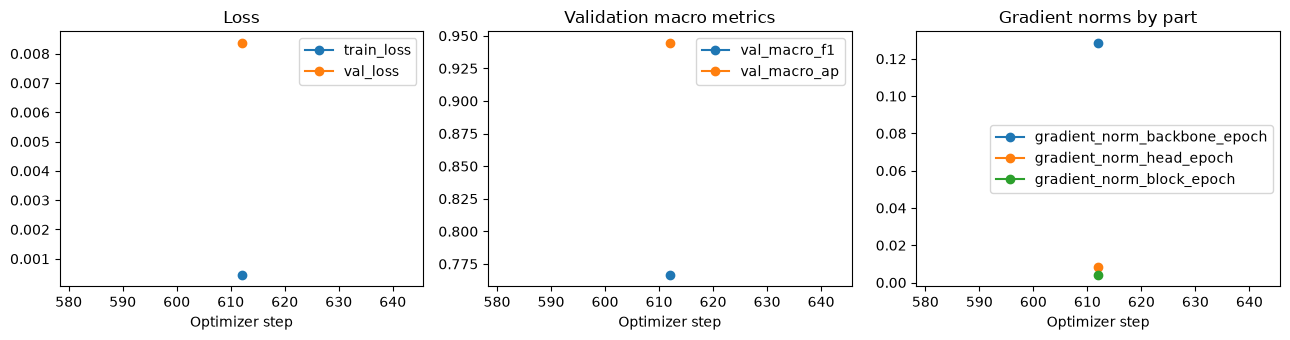

Saved curves: /Users/hermanhavva/Documents/Kse/deep_learning/deep-learning-assignment2/artifacts/convnext_custom_fold0_seed42_mps_gradcam1/curves.png


In [6]:
with record_failures(run_dir, failure_configuration, 'curves'):
    if RUN_TRAINING:
        import csv
        import matplotlib.pyplot as plt

        with (Path(logger.log_dir) / 'metrics.csv').open(newline='') as file:
            history = list(csv.DictReader(file))
        figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
        for axis, names, title in zip(
            axes,
            (('train_loss', 'val_loss'), ('val_macro_f1', 'val_macro_ap'), ('gradient_norm_backbone_epoch', 'gradient_norm_head_epoch', 'gradient_norm_block_epoch')),
            ('Loss', 'Validation macro metrics', 'Gradient norms by part'),
        ):
            for name in names:
                points = [(int(row['step']), float(row[name])) for row in history if row.get(name) not in (None, '')]
                if points:
                    axis.plot(*zip(*points), marker='o', label=name)
            axis.set(title=title, xlabel='Optimizer step')
            if axis.lines:
                axis.legend()
        figure.tight_layout()
        curves_path = run_dir / 'curves.png'
        figure.savefig(curves_path, dpi=140)
        plt.show()
        print('Saved curves:', curves_path)
        if drive_backup is not None:
            drive_backup.save_results([curves_path])
    else:
        print('No training curves to plot.')

## Evaluate a completed fold, not the smoke test

When the runtime gate permits the full run, reload the *best validation checkpoint*, not simply the last epoch, and predict all 2,452 fold-0 images in their saved order. For evaluation without training, set both `STAGE2_EVAL_CHECKPOINT` and `STAGE2_EVAL_RUN_RECORD` to the best checkpoint and its original completed-run JSON. The notebook verifies the checkpoint hash, fold/head hashes, label order and recorded recipe before loading checkpoint weights. Smoke/timing records and mismatched or legacy records without this provenance are rejected. Choose a fresh `STAGE2_RUN_ID`: predictions and an evaluation record are saved under `artifacts/<run-id>_evaluation/`, leaving the original run untouched. Keep the original pretrained weights and head file available: the notebook rebuilds the model before loading the checkpoint.

Report macro and per-label F1 at the fixed 0.25 threshold, average precision (which does not use that threshold), and F1 at 0.5 for context. The 0.25 threshold and checkpoint-selection metric are held fixed across the head-only and fine-tuned runs. A stopped timing probe or smoke test has no reportable quality score.


In [7]:
with record_failures(run_dir, failure_configuration, 'evaluation'):
    if EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded):
        checkpoint_path = Path(EVAL_CHECKPOINT).resolve() if EVAL_CHECKPOINT else Path(checkpoint.best_model_path)
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f'Missing full checkpoint: {checkpoint_path}')
        best_module = FineTuneClassifier.load_from_checkpoint(
            checkpoint_path, network=network, backbone_lr=BACKBONE_LR,
            head_lr=HEAD_LR, weight_decay=WEIGHT_DECAY, threshold=THRESHOLD,
        )
        prediction_started = time.perf_counter()
        predicted_ids, validation_probabilities = predict_probabilities(best_module, validation_loader, DEVICE)
        prediction_seconds = time.perf_counter() - prediction_started
        if predicted_ids != [row['image_id'] for row in validation_rows]:
            raise ValueError('Validation loader changed image order.')
        validation_targets = np.asarray([[int(row[label]) for label in LABEL_COLUMNS] for row in validation_rows])
        metrics = score_probabilities(validation_targets, validation_probabilities, THRESHOLD)
        diagnostic_metrics = score_probabilities(validation_targets, validation_probabilities, 0.5)
        print('Fold-0 metrics:', metrics)
        print('F1 at 0.5:', {'macro_f1': diagnostic_metrics['macro_f1'], 'per_label_f1': diagnostic_metrics['per_label_f1']})
    else:
        print('Full-fold evaluation skipped; smoke and timing-gate scores are not results.')


Full-fold evaluation skipped; smoke and timing-gate scores are not results.


## Look at where the model attends (optional)

Set `BUILD_GRADCAM=True` only after loading a completed best checkpoint. For each named-pet label, the cell chooses the first positive fold-0 image in the saved order and computes GradCAM from that label's logit, using the last pretrained spatial stage. It saves an overlay and the image ID. These fixed examples make the visual check reproducible, but three heatmaps cannot prove the model is adequate or that the custom block helped. For a fair visual comparison, use the same image IDs with the unchanged control.


In [8]:
with record_failures(run_dir, failure_configuration, 'gradcam'):
    gradcam_paths = []
    if BUILD_GRADCAM:
        if not (EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded)):
            raise ValueError('GradCAM needs a completed best checkpoint.')
        import matplotlib.pyplot as plt
        from stage2.gradcam import gradcam_map

        output_dir = run_dir / 'gradcam'
        output_dir.mkdir(parents=True, exist_ok=True)
        best_module.to(DEVICE).eval()
        for label in ('Moris', 'Motya', 'Biatrix'):
            index = next(i for i, row in enumerate(validation_rows) if row[label] == '1')
            image_id, normalized_image, _ = validation_data[index]
            heatmap = gradcam_map(best_module, normalized_image.unsqueeze(0).to(DEVICE), best_module.network.gradcam_target_layer, LABEL_COLUMNS.index(label)).cpu()
            mean = torch.tensor(preprocessing['mean'])[:, None, None]
            std = torch.tensor(preprocessing['std'])[:, None, None]
            display_image = (normalized_image * std + mean).clamp(0, 1).permute(1, 2, 0)
            figure, axis = plt.subplots(figsize=(5, 5))
            axis.imshow(display_image)
            axis.imshow(heatmap, cmap='magma', alpha=0.45, vmin=0, vmax=1)
            axis.set(title=f'{label}: {image_id}', xticks=[], yticks=[])
            path = output_dir / f'{label.lower()}_{image_id}.png'
            if path.exists():
                raise FileExistsError(f'Refusing to overwrite {path}')
            figure.savefig(path, dpi=140, bbox_inches='tight')
            plt.close(figure)
            gradcam_paths.append(path)
            print('Saved GradCAM:', path)
        if RUN_TRAINING and drive_backup is not None:
            drive_backup.save_results(gradcam_paths)
    else:
        print('GradCAM skipped.')

GradCAM skipped.


In [9]:
with record_failures(run_dir, failure_configuration, 'results'):
    if EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded):
        result_dir = run_dir if EVAL_CHECKPOINT else ROOT / 'experiments' / '02_convnext_custom' / 'results'
        probability_path = result_dir / f'{RUN_ID}_val.csv'
        record_path = result_dir / f'{RUN_ID}.json'
        for path in (probability_path, record_path):
            if path.exists():
                raise FileExistsError(f'Refusing to overwrite {path}')
        write_probabilities(probability_path, predicted_ids, validation_probabilities, VALIDATION_FOLD)
        git_commit = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, capture_output=True, text=True, check=True).stdout.strip() if (ROOT / '.git').exists() else None
        source_files = (ROOT / 'notebooks' / '07_convnext_custom.ipynb', ROOT / 'stage2' / 'experiment.py', ROOT / 'stage2' / 'train.py', ROOT / 'stage2' / 'finetune.py', ROOT / 'stage2' / 'custom_convnext.py', ROOT / 'stage2' / 'gradcam.py', ROOT / 'stage2' / 'run_records.py', ROOT / 'stage2' / 'diagnostics.py')
        source_sha256 = {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files}
        if EVAL_CHECKPOINT:
            record = {
                **source_run_record, 'run_id': RUN_ID, 'status': 'evaluated',
                'source_run_id': source_run_record['run_id'],
                'source_run_record': str(Path(EVAL_RUN_RECORD).resolve()),
                'source_run_record_sha256': file_sha256(Path(EVAL_RUN_RECORD)),
                'evaluation': {'git_commit': git_commit, 'source_sha256': source_sha256,
                               'device': str(DEVICE), 'prediction_seconds': prediction_seconds,
                               'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__}},
                'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_metrics['macro_f1'], 'per_label_f1_at_0_5': diagnostic_metrics['per_label_f1']},
                'artifacts': {**source_run_record['artifacts'],
                              'validation_probabilities_csv': str(probability_path.relative_to(ROOT)),
                              'evaluated_checkpoint': str(checkpoint_path),
                              'gradcam_images': [str(path.relative_to(ROOT)) for path in gradcam_paths]},
            }
        else:
            record = {
                **run_configuration,
                'run_id': RUN_ID, 'experiment': '02_convnext_custom', 'status': 'completed',
                'git_commit': git_commit, 'source_sha256': source_sha256,
                'training': {**run_configuration['training'], 'epochs_completed': trainer.fit_loop.epoch_progress.current.completed},
                'hardware': diagnostics.memory,
                'trainable_parameters': sum(p.numel() for p in network.parameters() if p.requires_grad),
                'metrics': {**metrics, 'macro_f1_at_0_5': diagnostic_metrics['macro_f1'], 'per_label_f1_at_0_5': diagnostic_metrics['per_label_f1']},
                'timings': {'training_and_validation_seconds': training_seconds, 'epoch_seconds': checkpoint.epoch_seconds,
                            'first_epoch_projected_seconds': checkpoint.projected_seconds, 'best_checkpoint_prediction_seconds': prediction_seconds},
                'artifacts': {'validation_probabilities_csv': str(probability_path.relative_to(ROOT)),
                              'best_checkpoint_local': str(checkpoint_path.relative_to(ROOT)),
                              'best_checkpoint_sha256': file_sha256(checkpoint_path),
                              'curves_csv': str((Path(logger.log_dir) / 'metrics.csv').relative_to(ROOT)),
                              'layer_gradients_csv': str((run_dir / 'diagnostics' / 'layer_gradients.csv').relative_to(ROOT)),
                              'memory_json': str((run_dir / 'diagnostics' / 'memory.json').relative_to(ROOT)),
                              'gradcam_images': [str(path.relative_to(ROOT)) for path in gradcam_paths],
                              'drive_backup_dir': str(drive_backup.drive_dir) if drive_backup is not None else None},
                'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__, 'lightning': L.__version__},
                'telemetry': {'wandb_enabled': USE_WANDB, 'wandb_mode': WANDB_MODE if USE_WANDB else None,
                              'wandb_project': WANDB_PROJECT if USE_WANDB else None,
                              'wandb_run_id': wandb_logger.version if wandb_logger is not None else None, 'model_upload': False},
                'public_leaderboard_score': None, 'error': None,
            }
        write_run_record(record_path, record)
        print('Saved:', record_path, probability_path, sep='\n')
        if RUN_TRAINING and drive_backup is not None:
            drive_backup.save_results([record_path, probability_path])
    else:
        print('No full-run artifacts written.')


No full-run artifacts written.


## Compare against the unchanged control

If `STAGE2_CONTROL_RUN_ID` points to a completed standard ConvNeXt run, check its recorded fold, starting weights, data processing, threshold, scheduler, effective batch, precision, and checkpoint rule before showing a score difference. The comparison uses the original custom and standard run records, including optimizer settings, epoch cap, patience, and content hashes for the starting head and saved folds. Records missing this provenance are rejected. A numerical difference alone does not establish that the block caused it.


In [10]:
with record_failures(run_dir, failure_configuration, 'comparison'):
    if CONTROL_RUN_ID and (EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded)):
        import json

        control_path = ROOT / 'experiments' / '01_convnext_standard' / 'results' / f'{CONTROL_RUN_ID}.json'
        control_record = json.loads(control_path.read_text())
        comparison_record = source_run_record if EVAL_CHECKPOINT else record
        checks = validate_matched_control(comparison_record, control_record)
        print('Shared recorded settings matched:', ', '.join(checks))
        print(f"Fold-0 macro F1 difference (custom minus control): {metrics['macro_f1'] - control_record['metrics']['macro_f1']:+.5f}")
        print('Per-label F1 differences:', {label: round(metrics['per_label_f1'][label] - control_record['metrics']['per_label_f1'][label], 5) for label in LABEL_COLUMNS})
        print('Differences below 0.005 macro F1 are within the practical noise floor; fold 0 is screening only.')
    else:
        print('Matched control comparison pending.')


Matched control comparison pending.


## Make a submission file, if we want one

Only do this after reviewing the validation result. With `BUILD_SUBMISSION=True`, the notebook predicts the test images and writes a CSV in the same order as `sample_submission.csv`. It checks the IDs and column names before writing.

This creates a local file; it does not upload anything. Kaggle submission and recording the public score are separate manual steps. `SUBMIT_TO_KAGGLE` remains false and has no submission code attached to it.

In [11]:
with record_failures(run_dir, failure_configuration, 'submission'):
    if BUILD_SUBMISSION:
        if not (EVAL_CHECKPOINT or (RUN_TRAINING and not SMOKE_TEST and not PROFILE_ONLY and not budget_exceeded)):
            raise ValueError('Build a submission only after a complete fold run.')
        test_data = ImageDataset(test_rows, DATA_DIR / 'test', IMAGE_SIZE, preprocessing['mean'], preprocessing['std'])
        test_loader = DataLoader(test_data, shuffle=False, **loader_options)
        test_ids, test_probabilities = predict_probabilities(best_module, test_loader, DEVICE)
        submission_rows = form_submission(DATA_DIR / 'sample_submission.csv', test_ids, test_probabilities, THRESHOLD)
        submission_dir = run_dir
        submission_path = submission_dir / f'{RUN_ID}_submission.csv'
        write_submission(submission_path, submission_rows)
        print('CSV ready for manual review:', submission_path)
        if RUN_TRAINING and drive_backup is not None:
            drive_backup.save_results([submission_path])
    else:
        print('No submission CSV built or uploaded.')

No submission CSV built or uploaded.


## Read the comparison carefully

The main comparison is with a completed, unchanged ConvNeXt fold-0 control using this same recipe; put its ID in `STAGE2_CONTROL_RUN_ID` and verify its settings before attributing a difference to the block. The head-only fold-0 F1 of 0.93577 is useful context, not a substitute for that control. Inspect named-pet scores, loss curves, gradient flow, extra parameters and runtime as well as macro F1. The old five-fold 0.957 and public 0.92922 numbers answer different questions. GradCAM and broader fold evaluation remain necessary for the assignment's final claim.

Before leaving Colab, preserve the CLI-generated output-bearing notebook alongside the run JSON and CSV. Drive holds the training artifacts when backup is enabled, but this notebook's displayed outputs are a separate record. Do not claim a public leaderboard improvement until a reviewed submission has actually been uploaded and scored.
